In [1]:
from mhcicleave.lightning_model import CleavageLightningModule
from mhcicleave.models import MLP


In [2]:
seq_len = 10 # Asegúrate que esto coincide con tus datos
esm2_dim = 1280
input_size_mlp = seq_len * esm2_dim

# Elige qué modelo usar
# Modelo MLP:
model_params_mlp = {"input_size": input_size_mlp, "hidden_linear1": 256, "hidden_linear2": 128, "out_neurons": 1, "dropout": 0.5}
mlp_model_instance  = MLP(**model_params_mlp)

In [3]:
checkpoint_path = "csv_logs/esm2_MLP_final/version_2/checkpoints/best_model-epoch=13-val_loss=0.32.ckpt"

In [4]:
lightning_model = CleavageLightningModule.load_from_checkpoint(checkpoint_path=checkpoint_path, model=mlp_model_instance)


/home/vilion/miniforge3/envs/pLM/lib/python3.12/site-packages/torchmetrics/utilities/prints.py:43: FutureWarning: The default value for `maximize` will be changed from `True` to `None` in v1.7.0 of TorchMetrics,will automatically infer the value based on the `higher_is_better` attribute of the metric (if such attribute exists) or raise an error if it does not. If you are explicitly setting the `maximize` argument to either `True` or `False` already, you can ignore this warning.
  warnings.warn(*args, **kwargs)


Cargando métricas desde: csv_logs/esm2_MLP_final/version_2/metrics.csv

Columnas disponibles:
Index(['epoch', 'step', 'train_BinaryAUROC', 'train_BinaryAccuracy',
       'train_BinaryMatthewsCorrCoef', 'train_loss', 'val_loss',
       'valid_BinaryAUROC', 'valid_BinaryAccuracy',
       'valid_BinaryMatthewsCorrCoef'],
      dtype='object')


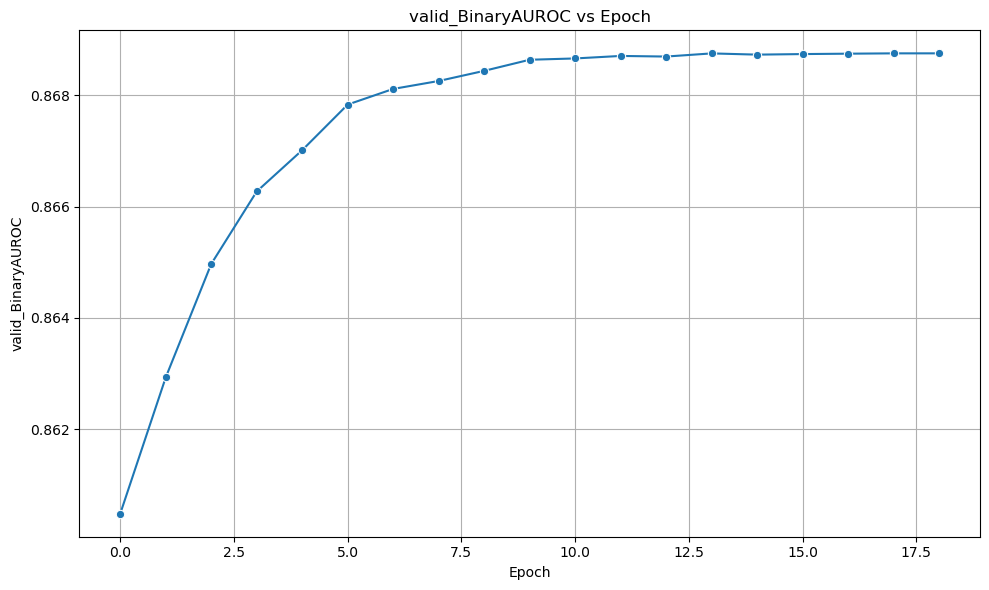

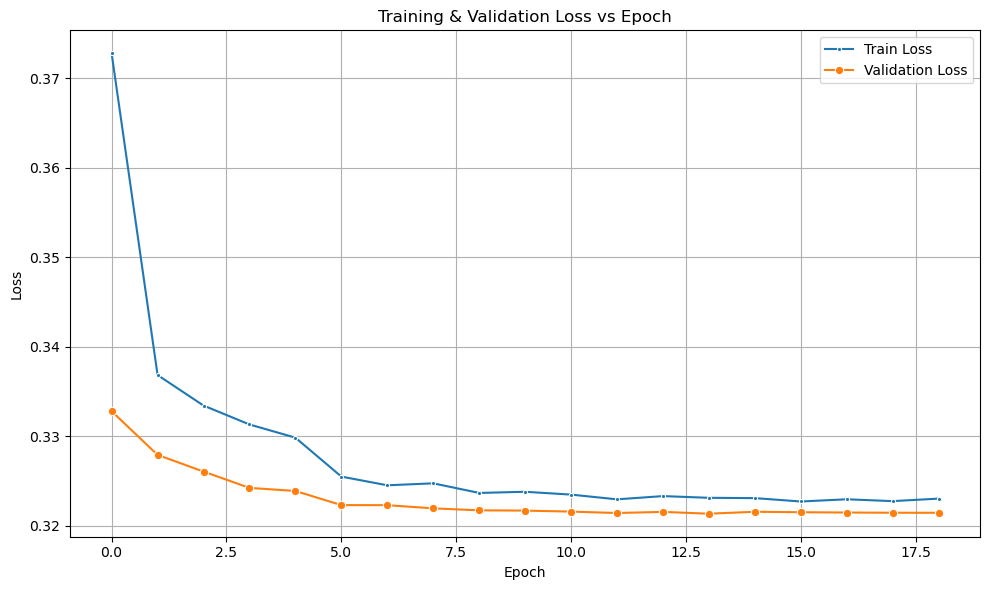

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# --- 1. Define la ruta al archivo metrics.csv generado por CSVLogger ---
# Esto estará dentro del directorio que se imprimió al final del entrenamiento
# (Ej: csv_logs/esm2_MLP_final/version_X/metrics.csv)
# ¡¡¡ REEMPLAZA CON LA RUTA REAL A TU ARCHIVO metrics.csv !!!
log_dir = Path("csv_logs/esm2_MLP_final/version_2/") # Ajusta version_X
metrics_file = log_dir / "metrics.csv"

if not metrics_file.is_file():
    print(f"ERROR: Archivo de métricas no encontrado en: {metrics_file}")
    # Salir o manejar el error
else:
    print(f"Cargando métricas desde: {metrics_file}")
    metrics_df = pd.read_csv(metrics_file)

    # --- 2. Explorar y Graficar ---
    print("\nColumnas disponibles:")
    print(metrics_df.columns)
    # Ejemplo: Index(['step', 'train_loss', 'epoch', 'valid_loss', 'train_AUROC',
    #                'train_Accuracy', 'train_MatthewsCorrCoef', 'val_AUROC',
    #                'val_Accuracy', 'val_MatthewsCorrCoef'])

    # Eliminar filas con NaNs (pueden aparecer para métricas de validación en pasos de entrenamiento)
    metrics_df = metrics_df.dropna(subset=['epoch']) # Asegurarse que la época existe
    metrics_df['epoch'] = metrics_df['epoch'].astype(int) # Convertir época a entero

    # --- Graficar una métrica específica (ej: AUROC de validación vs epoch) ---

    # Asegurarse de que la métrica existe y no tiene NaNs para el plot
    metric_to_plot = 'valid_BinaryAUROC'
    if metric_to_plot in metrics_df.columns:
        # Agrupar por época y tomar la última métrica registrada para esa época (o promedio, etc.)
        # CSVLogger a veces guarda valores por step y por epoch end. Queremos los de epoch end.
        # Filtraremos por las filas que tengan un valor válido para la métrica de validación deseada
        plot_data = metrics_df.dropna(subset=[metric_to_plot])
        # Si hay múltiples valores por época, podrías agrupar: plot_data.groupby('epoch').last() o .mean()

        plt.figure(figsize=(10, 6))
        sns.lineplot(data=plot_data, x='epoch', y=metric_to_plot, marker='o')
        plt.title(f'{metric_to_plot} vs Epoch')
        plt.xlabel('Epoch')
        plt.ylabel(metric_to_plot)
        plt.grid(True)
        plt.tight_layout()
        # Guardar o mostrar el gráfico
        # plt.savefig(log_dir / f"{metric_to_plot}_history.png")
        plt.show()
    else:
        print(f"ERROR: La métrica '{metric_to_plot}' no se encontró en las columnas del CSV o no tiene valores válidos.")

    # --- Graficar pérdidas (train y validation) ---
    plt.figure(figsize=(10, 6))
    # Plot train_loss (puede haber valores por step, filtramos para epoch end si es necesario o ploteamos todo)
    sns.lineplot(data=metrics_df.dropna(subset=['train_loss']), x='epoch', y='train_loss', label='Train Loss', marker='.')
    # Plot val_loss (generalmente solo hay un valor al final de la época)
    sns.lineplot(data=metrics_df.dropna(subset=['val_loss']), x='epoch', y='val_loss', label='Validation Loss', marker='o')

    plt.title('Training & Validation Loss vs Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(log_dir / "loss_history.png")
    plt.show()